In [70]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [71]:
mnist = fetch_openml (
    name = "mnist_784",
    version = 1,
    as_frame = False
)

X = mnist.data
y = mnist.target
print(X.shape, y.shape, X[0], type(y[0]))

(70000, 784) (70000,) [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255
 247 127   0   0   0   0   0   0   0   0   0   0   0   0  30  36  94 154
 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0   0   0
   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82
  82  56  39   0   0   0   0   0   0   0   0   0   0   0   0  18 219 253
 253 253 253 253 198 182 247 

In [110]:
print("Размеры выборок:")
print(f"Обучающая выборка X_train: {X_train.shape}")
print(f"Метки обучающей выборки y_train: {y_train.shape}")
print(f"Тестовая выборка X_test: {X_test.shape}")
print(f"Метки тестовой выборки y_test: {y_test.shape}")

Размеры выборок:
Обучающая выборка X_train: (60000, 784)
Метки обучающей выборки y_train: (60000,)
Тестовая выборка X_test: (10000, 784)
Метки тестовой выборки y_test: (10000,)


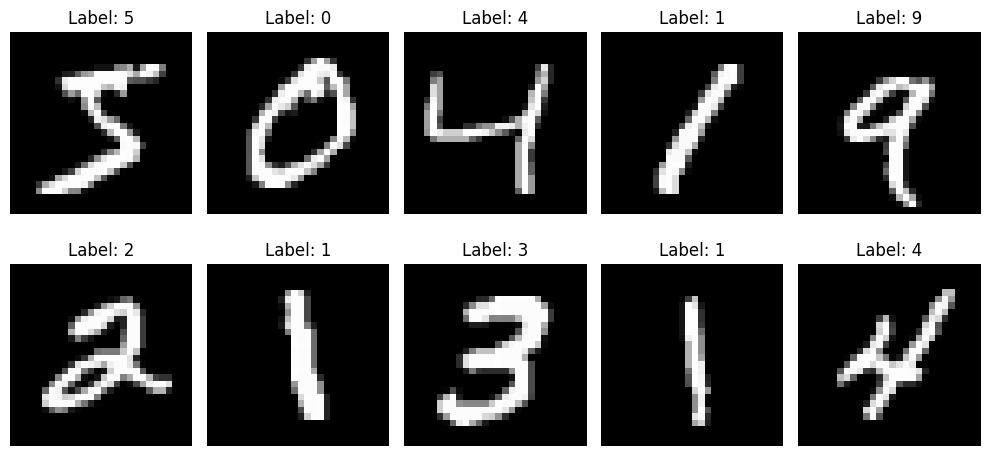

In [72]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = X[i].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [73]:
def preprocessing(X, y):
  X = X.astype(np.float32) / 255.0
  y = y.astype(np.int64)

  X_train, X_test = X[:60000], X[60000:]
  y_train, y_test = y[:60000], y[60000:]

  return X_train, X_test, y_train, y_test

In [74]:
X_train, X_test, y_train, y_test = preprocessing(X, y)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(X_train.min(), X_train.max())

(60000, 784) (10000, 784) (60000,) (10000,)
0.0 1.0


In [75]:
def initialize_parameters(input_size, hidden_size, output_size):
  W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
  W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
  b1 = np.zeros((1, hidden_size))
  b2 = np.zeros((1, output_size))

  return W1, b1, W2, b2

In [76]:
W1, b1, W2, b2 = initialize_parameters(784, 300, 10)
print(W1.shape, b1.shape, W2.shape, b2.shape)

(784, 300) (1, 300) (300, 10) (1, 10)


In [77]:
def relu(x):
  return np.maximum(0, x)

def softmax(x):
  exp_x = np.exp(x)
  return exp_x / np.sum(exp_x, axis=1, keepdims=True)

def forward(X, W1, b1, W2, b2):
  Z1 = X @ W1 + b1
  A1 = relu(Z1)
  Z2 = A1 @ W2 + b2
  Y_hat = softmax(Z2)

  return Y_hat, Z1, A1

In [78]:
def cross_entropy(Y_hat, y):
  correct_probs = Y_hat[np.arange(len(y)), y]
  correct_probs = np.clip(correct_probs, 1e-12, 1.0)
  loss = - np.mean(np.log(correct_probs))
  return loss

In [79]:
def one_hot_encoding(y, num_classes = 10):
  y_encoded = np.zeros((y.size, num_classes))
  y_encoded[np.arange(y.size), y] = 1
  return y_encoded

In [80]:
print(one_hot_encoding(y_train[:8]).shape)

(8, 10)


In [81]:
def backward(X, Y_hat, Z1, A1, W2, y):
  B = y.size
  Y = one_hot_encoding(y)

  dZ2 = (Y_hat - Y) / B
  dW2 = A1.T @ dZ2
  db2 = np.sum(dZ2, axis = 0, keepdims = True)

  dZ1 = (dZ2 @ W2.T) * (Z1 > 0)
  dW1 = X.T @ dZ1
  db1 = np.sum(dZ1, axis = 0, keepdims = True)

  return dW1, db1, dW2, db2

In [82]:
def upgrade_parameters(W1, b1, W2, b2, grads, learning_rate = 0.1):
  dW1, db1, dW2, db2 = grads

  W1 = W1 - learning_rate * dW1
  b1 = b1 - learning_rate * db1
  W2 = W2 - learning_rate * dW2
  b2 = b2 - learning_rate * db2

  return W1, b1, W2, b2

In [83]:
def predict(X, W1, b1, W2, b2):
  Y_hat, _, _ = forward(X, W1, b1, W2, b2)
  predictions = np.argmax(Y_hat, axis = 1)

  return predictions

In [84]:
def classification_error(y_true, y_pred):
    return np.mean(y_true != y_pred)

In [85]:
import time
def train(X_train, y_train, X_test, y_test,
          hidden_size=300, learning_rate=0.1,
          batch_size=32, epochs=20):

  W1, b1, W2, b2 = initialize_parameters(784, hidden_size, 10)

  for epoch in range(epochs):
    indices = np.random.permutation(len(X_train))

    start_time = time.time()

    for start in range(0, len(X_train), batch_size):
      batch_indices = indices[start:start + batch_size]
      X_batch = X_train[batch_indices]
      y_batch = y_train[batch_indices]

      Y_hat, Z1, A1 = forward(X_batch, W1, b1, W2, b2)
      grads = backward(X_batch, Y_hat, Z1, A1, W2, y_batch)
      W1, b1, W2, b2 = upgrade_parameters(W1, b1, W2, b2, grads, learning_rate=learning_rate)

    train_predictions = predict(X_train, W1, b1, W2, b2)
    train_error = classification_error(y_train, train_predictions)

    test_predictions = predict(X_test, W1, b1, W2, b2)
    test_error = classification_error(y_test, test_predictions)

    epoch_time = time.time() - start_time

    print(
    f"Epoch {epoch + 1}/{epochs} | "
    f"Train error: {train_error:.4f} | "
    f"Test error: {test_error:.4f} | "
    f"Time: {epoch_time:.2f}s"
    )

  return W1, b1, W2, b2

In [86]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (60000, 784)
y_train: (60000,)
X_test: (10000, 784)
y_test: (10000,)


In [87]:
W1, b1, W2, b2 = train(
    X_train, y_train, X_test, y_test,
    hidden_size=300,
    learning_rate=0.1,
    batch_size=32,
    epochs=20
)

Epoch 1/20 | Train error: 0.0469 | Test error: 0.0490 | Time: 9.43s
Epoch 2/20 | Train error: 0.0282 | Test error: 0.0336 | Time: 6.29s
Epoch 3/20 | Train error: 0.0207 | Test error: 0.0277 | Time: 9.71s
Epoch 4/20 | Train error: 0.0165 | Test error: 0.0265 | Time: 6.54s
Epoch 5/20 | Train error: 0.0118 | Test error: 0.0241 | Time: 9.57s
Epoch 6/20 | Train error: 0.0092 | Test error: 0.0219 | Time: 7.13s
Epoch 7/20 | Train error: 0.0082 | Test error: 0.0210 | Time: 7.96s
Epoch 8/20 | Train error: 0.0071 | Test error: 0.0200 | Time: 9.66s
Epoch 9/20 | Train error: 0.0053 | Test error: 0.0207 | Time: 6.55s
Epoch 10/20 | Train error: 0.0036 | Test error: 0.0186 | Time: 9.63s
Epoch 11/20 | Train error: 0.0028 | Test error: 0.0192 | Time: 6.39s
Epoch 12/20 | Train error: 0.0017 | Test error: 0.0194 | Time: 9.47s
Epoch 13/20 | Train error: 0.0017 | Test error: 0.0189 | Time: 7.06s
Epoch 14/20 | Train error: 0.0016 | Test error: 0.0199 | Time: 7.86s
Epoch 15/20 | Train error: 0.0015 | Test er

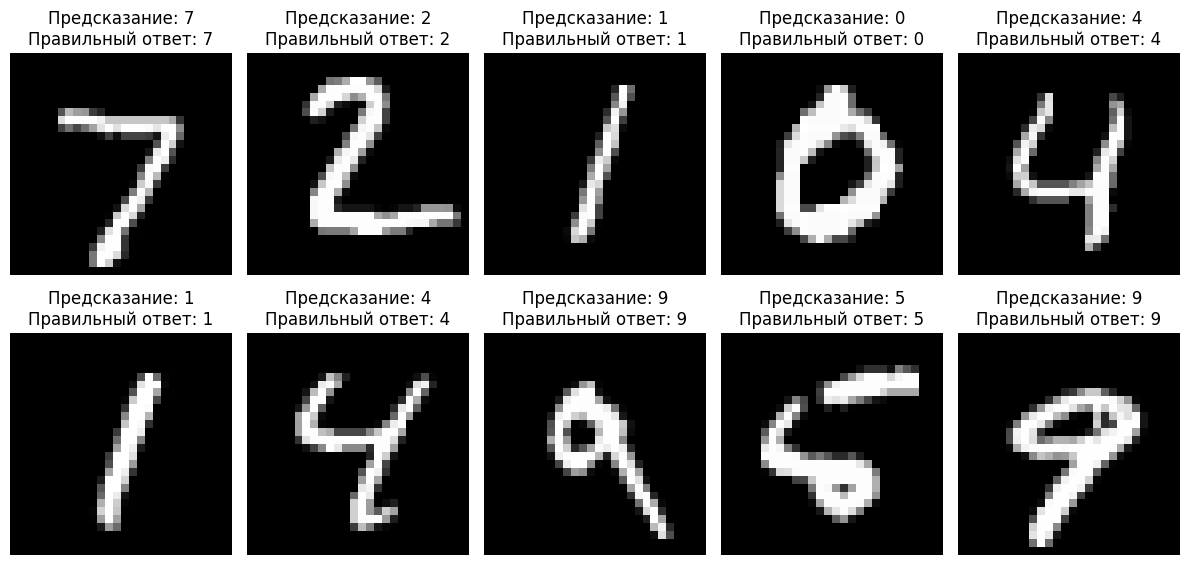

In [90]:
def show_predictions(X, y, W1, b1, W2, b2, num_images=10):
    predictions = predict(X[:num_images], W1, b1, W2, b2)

    fig, axes = plt.subplots(2, 5, figsize=(12, 6))

    for i, ax in enumerate(axes.flat):
        image = X[i].reshape(28, 28)

        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"Предсказание: {predictions[i]}\n"
            f"Правильный ответ: {y[i]}",
            color="black" if predictions[i] == y[i] else "red"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(X_test, y_test, W1, b1, W2, b2)

In [89]:
test_predictions = predict(X_test, W1, b1, W2, b2)

test_error = classification_error(y_test, test_predictions)
test_accuracy = 1 - test_error

correct = np.sum(test_predictions == y_test)
incorrect = np.sum(test_predictions != y_test)

print(f"Размер тестовой выборки: {len(y_test)}")
print(f"Правильных ответов: {correct}")
print(f"Ошибочных ответов: {incorrect}")
print(f"Точность: {test_accuracy * 100:.2f}%")
print(f"Ошибка классификации: {test_error * 100:.2f}%")

Размер тестовой выборки: 10000
Правильных ответов: 9817
Ошибочных ответов: 183
Точность: 98.17%
Ошибка классификации: 1.83%


In [103]:
pip install nbconvert

In [109]:
!jupyter nbconvert --to html "/content/lab1_BozinDO.ipynb"

[NbConvertApp] Converting notebook /content/lab1_BozinDO.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 389416 bytes to /content/lab1_BozinDO.html
